# EDA: продажи и Telegram-публикации

In [1]:
from pathlib import Path
import sys, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/experiments/posts.py").exists())
sys.path.insert(0, str(repo_root / "src"))
from experiments.posts import clean_text, classify_posts, LABELS
pd.set_option("display.max_colwidth", 140)
CHART_DIR = repo_root / "outputs/charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)


## 1. Продажи: загрузка и очистка

In [2]:
base = pd.read_csv(repo_root / "data/raw/base.csv")

required = {"Номер студента", "Сумма", "Курс", "Время"}
missing = required - set(base.columns)
assert not missing, f"Не хватает колонок: {missing}"

sales = base.copy()

sales["Сумма"] = pd.to_numeric(
    sales["Сумма"]
        .astype(str)
        .str.replace(r"[\s\u00a0]", "", regex=True)
        .str.replace(",", ".", regex=False),
    errors="raise",
)

sales["Время"] = pd.to_datetime(
    sales["Время"],
    format="%d.%m.%Y %H:%M:%S",
    errors="raise",
)

sales["Курс"] = sales["Курс"].astype(str).str.strip()

print("Строк:", len(sales))
print("Период:", sales["Время"].min(), "—", sales["Время"].max())
print("Пропуски:")
display(sales.isna().sum().to_frame("missing"))
display(sales.head())

Строк: 795
Период: 2026-08-04 09:08:31 — 2026-09-10 06:09:12
Пропуски:


,missing
Номер студента,0
Сумма,0
Курс,0
Время,0


,Номер студента,Сумма,Курс,Время
0,437,8950.0,ML про,2026-08-04 09:08:31
1,437,7890.0,Аналитика старт,2026-08-04 09:35:00
2,443,8475.0,Линейная алгебра,2026-08-04 10:14:38
3,443,8475.0,Мат анализ,2026-08-04 10:14:38
4,430,8950.0,К ВУЗу,2026-08-04 13:38:06


### Уровень заказа

Одна строка исходной таблицы — не обязательно отдельная покупка. Если один студент в один timestamp имеет несколько курсов, это bundle: несколько `order_item` внутри одного заказа.

Поэтому:
- выручку по продуктам можно считать по исходным строкам;
- число заказов, средний чек заказа и repeat purchase нужно считать по агрегированной таблице `orders`.

In [3]:
orders = (
    sales
    .groupby(["Номер студента", "Время"], as_index=False)
    .agg(
        order_amount=("Сумма", "sum"),
        courses=("Курс", list),
        n_items=("Курс", "size"),
    )
    .sort_values(["Номер студента", "Время"])
)

orders["order_id"] = np.arange(1, len(orders) + 1)
orders["purchase_number"] = orders.groupby("Номер студента").cumcount() + 1
orders["is_repeat"] = orders["purchase_number"] > 1
orders["date"] = orders["Время"].dt.floor("D")

assert np.isclose(orders["order_amount"].sum(), sales["Сумма"].sum())
assert len(orders) == sales[["Номер студента", "Время"]].drop_duplicates().shape[0]

display(orders.head())

,Номер студента,Время,order_amount,courses,n_items,order_id,purchase_number,is_repeat,date
0,1,2026-09-04 19:30:57,8950.0,[Аналитика старт],1,1,1,False,2026-09-04
1,2,2026-09-05 16:22:48,8950.0,[ML про],1,2,1,False,2026-09-05
2,3,2026-09-03 22:47:02,5975.0,[АВ тестам],1,3,1,False,2026-09-03
3,4,2026-08-31 15:42:34,8950.0,[AI агенты],1,4,1,False,2026-08-31
4,5,2026-08-22 16:19:00,5750.0,[ML про],1,5,1,False,2026-08-22


## 2. Основные метрики

In [4]:
metrics = pd.Series({
    "Строк продуктов": len(sales),
    "Заказов": len(orders),
    "Уникальных покупателей": orders["Номер студента"].nunique(),
    "Продуктов": sales["Курс"].nunique(),
    "Выручка, ₽": orders["order_amount"].sum(),
    "Средний чек заказа, ₽": orders["order_amount"].mean(),
    "Медианный чек заказа, ₽": orders["order_amount"].median(),
    "Bundle-заказов": (orders["n_items"] > 1).sum(),
    "Повторных покупателей": (orders.groupby("Номер студента").size() > 1).sum(),
})

repeat_share = (
    (orders.groupby("Номер студента").size() > 1).mean() * 100
)

summary = pd.DataFrame({
    "Метрика": [
        "Строк продуктов",
        "Заказов",
        "Уникальных покупателей",
        "Продуктов",
        "Выручка, ₽",
        "Средний чек заказа, ₽",
        "Медианный чек заказа, ₽",
        "Bundle-заказов",
        "Повторных покупателей",
        "Доля повторных покупателей, %",
    ],
    "Значение": [
        len(sales),
        len(orders),
        orders["Номер студента"].nunique(),
        sales["Курс"].nunique(),
        round(orders["order_amount"].sum(), 2),
        round(orders["order_amount"].mean(), 2),
        round(orders["order_amount"].median(), 2),
        (orders["n_items"] > 1).sum(),
        (orders.groupby("Номер студента").size() > 1).sum(),
        round(repeat_share, 2),
    ],
})

display(summary)

,Метрика,Значение
0,Строк продуктов,795.00
1,Заказов,628.00
2,Уникальных покупателей,606.00
3,Продуктов,18.00
4,"Выручка, ₽",5904671.67
5,"Средний чек заказа, ₽",9402.34
6,"Медианный чек заказа, ₽",8950.00
7,Bundle-заказов,153.00
8,Повторных покупателей,20.00
9,"Доля повторных покупателей, %",3.30


## 3. Продукты и выручка

,Курс,revenue,item_rows,buyers
11,Аналитика про,740941.50,93,92
5,ML про,715110.00,90,90
0,AI агенты,711673.00,91,90
12,Аналитика старт,641616.50,91,91
10,Алгоритмы старт,529851.68,88,88
6,ML старт,523278.33,80,80
1,Backend про,438342.50,55,55
9,Алгоритмы про,268409.00,35,35
2,Backend старт,263396.66,39,39
8,Алгоритмы,209482.50,30,30


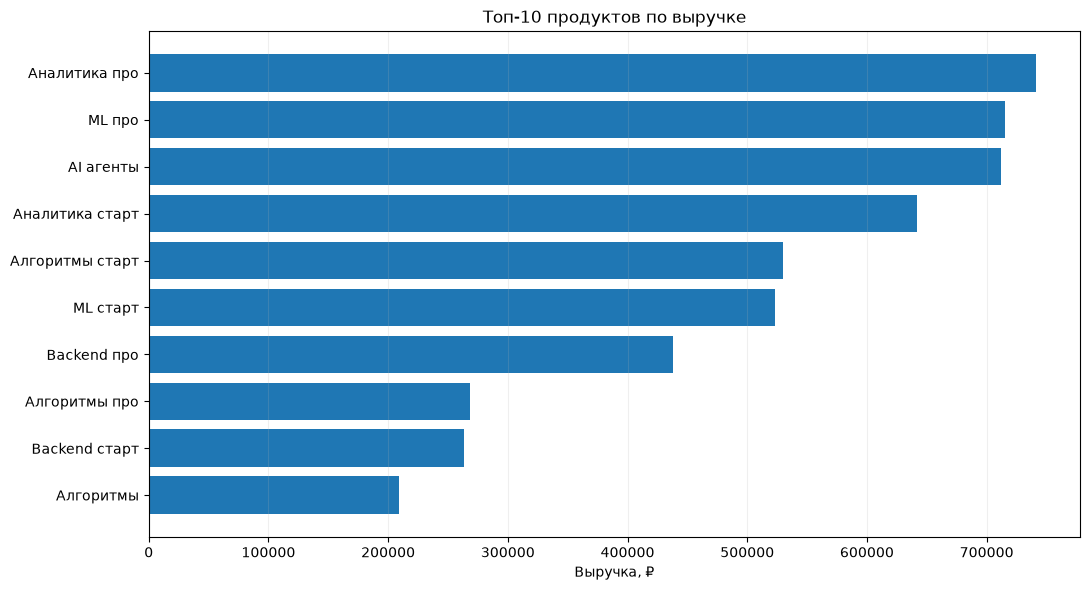

In [5]:
product_summary = (
    sales.groupby("Курс", as_index=False)
    .agg(
        revenue=("Сумма", "sum"),
        item_rows=("Курс", "size"),
        buyers=("Номер студента", "nunique"),
    )
    .sort_values("revenue", ascending=False)
)

display(product_summary)

fig, ax = plt.subplots(figsize=(11, 6))
top = product_summary.head(10).sort_values("revenue")
ax.barh(top["Курс"], top["revenue"])
ax.set_title("Топ-10 продуктов по выручке")
ax.set_xlabel("Выручка, ₽")
ax.set_ylabel("")
ax.grid(axis="x", alpha=.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "product_revenue.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Динамика спроса внутри доступного периода

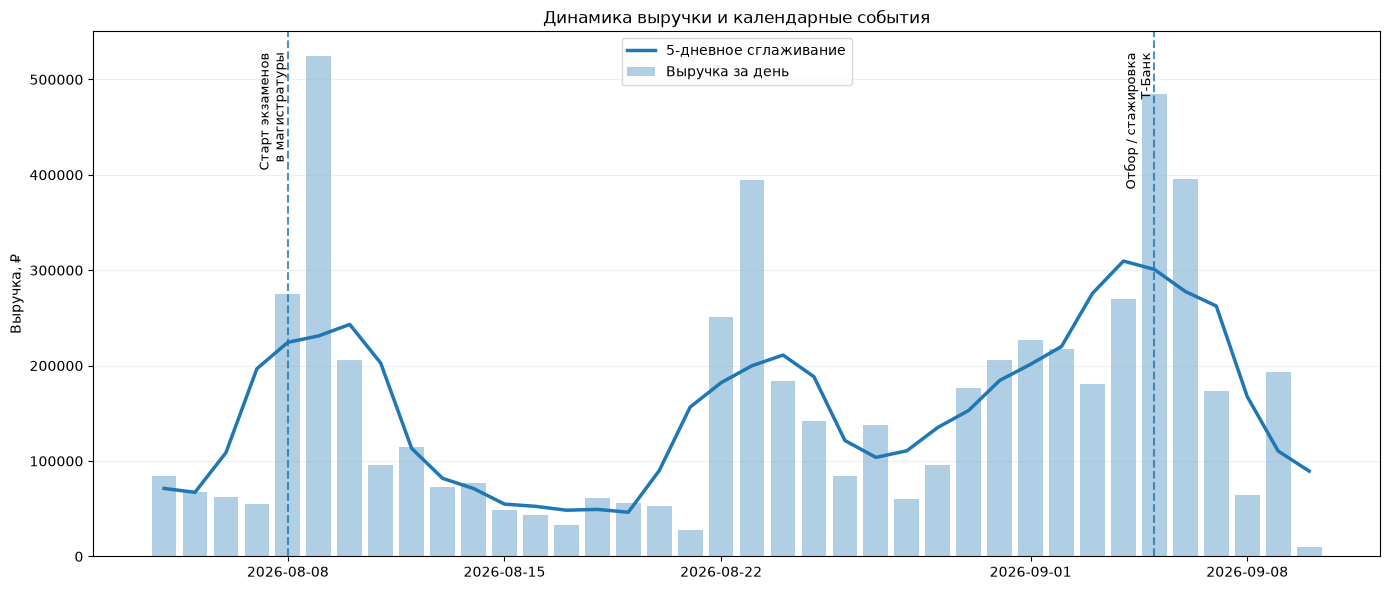

In [6]:
daily = (
    orders.groupby("date", as_index=False)
    .agg(
        revenue=("order_amount", "sum"),
        orders=("order_id", "count"),
        buyers=("Номер студента", "nunique"),
    )
)

calendar = pd.DataFrame({
    "date": pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
})
daily = calendar.merge(daily, on="date", how="left").fillna(
    {"revenue": 0, "orders": 0, "buyers": 0}
)

daily["revenue_ma5"] = daily["revenue"].rolling(5, center=True, min_periods=1).mean()
daily["orders_ma5"] = daily["orders"].rolling(5, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(daily["date"], daily["revenue"], alpha=.35, label="Выручка за день")
ax.plot(daily["date"], daily["revenue_ma5"], linewidth=2.5, label="5-дневное сглаживание")

# Известные внешние события — контекст, не доказательство причинности.
events_calendar = {
    pd.Timestamp("2026-08-08"): "Старт экзаменов\nв магистратуры",
    pd.Timestamp("2026-09-05"): "Отбор / стажировка\nТ-Банк",
}
for dt, label in events_calendar.items():
    ax.axvline(dt, linestyle="--", alpha=.8)
    ax.text(dt, ax.get_ylim()[1] * .96, label, rotation=90, va="top", ha="right", fontsize=9)

ax.set_title("Динамика выручки и календарные события")
ax.set_ylabel("Выручка, ₽")
ax.set_xlabel("")
ax.grid(axis="y", alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(CHART_DIR / "sales_demand_profile.png", dpi=160, bbox_inches="tight")
plt.show()

### Как интерпретировать этот график

Сглаженная линия показывает изменение спроса внутри 38-дневного периода. Вертикальные линии — известные внешние события, которые могут совпадать с изменением спроса.

Это **не оценка сезонности в строгом смысле**: для годовой сезонности нужен более длинный ряд, желательно несколько циклов. Здесь корректнее говорить о календарном спросе / demand pattern в доступном периоде.

## 5. Повторные покупки — после исправления bundle

n_orders
1    586
2     19
4      1
Name: buyers, dtype: int64

count    22.000000
mean     13.242406
std      10.380178
min       0.018391
25%       2.588492
50%      12.943397
75%      23.865185
max      28.527859
Name: days_since_prev, dtype: float64

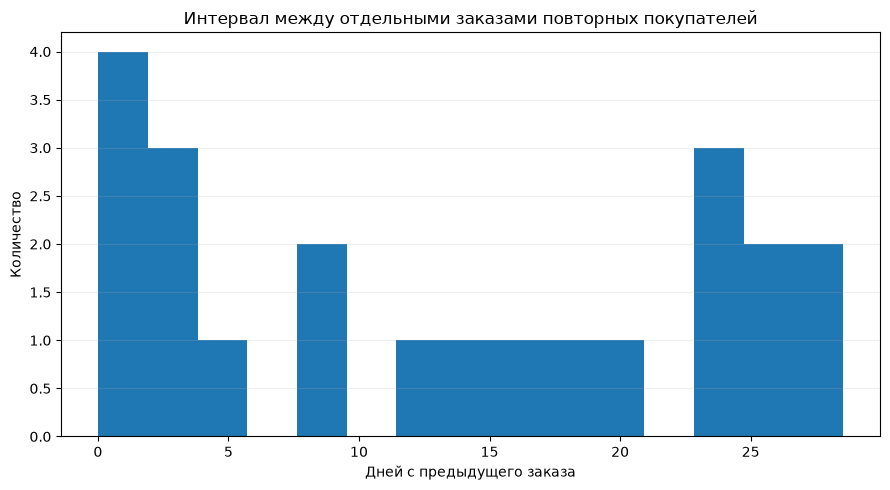

In [7]:
buyer_orders = (
    orders.groupby("Номер студента")
    .agg(
        n_orders=("order_id", "count"),
        first_order=("Время", "min"),
        last_order=("Время", "max"),
        revenue=("order_amount", "sum"),
    )
)

repeat_buyers = buyer_orders[buyer_orders["n_orders"] > 1]

# Интервалы только между РАЗНЫМИ заказами.
order_times = orders[["Номер студента", "Время", "purchase_number"]].copy()
order_times["prev_time"] = order_times.groupby("Номер студента")["Время"].shift(1)
order_times["days_since_prev"] = (
    order_times["Время"] - order_times["prev_time"]
).dt.total_seconds() / 86400

display(buyer_orders["n_orders"].value_counts().sort_index().rename("buyers"))
display(order_times.loc[order_times["purchase_number"] > 1, "days_since_prev"].describe())

fig, ax = plt.subplots(figsize=(9, 5))
vals = order_times.loc[order_times["purchase_number"] > 1, "days_since_prev"].dropna()
ax.hist(vals, bins=min(15, max(5, len(vals))))
ax.set_title("Интервал между отдельными заказами повторных покупателей")
ax.set_xlabel("Дней с предыдущего заказа")
ax.set_ylabel("Количество")
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
fig.savefig(CHART_DIR / "repeat_purchase_interval.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Telegram: загрузка и нормализация

In [8]:
tg_raw = json.loads((repo_root / "data/raw/tg_posts_text.json").read_text())
tg = pd.DataFrame([m for m in tg_raw["messages"] if m.get("type") == "message"])
posts = pd.DataFrame({
    "post_id": tg["id"],
    "event_timestamp": pd.to_datetime(tg["date"], errors="coerce"),
    "post_text": tg["text"].apply(clean_text),
})

posts = posts.dropna(subset=["event_timestamp"]).copy()

analysis_start = orders["Время"].min().floor("D")
analysis_end = orders["Время"].max().floor("D") + pd.Timedelta(days=1)

analysis_posts = posts[
    (posts["event_timestamp"] >= analysis_start) &
    (posts["event_timestamp"] < analysis_end)
].copy()

empty_messages = analysis_posts.post_text.str.strip().eq("").sum()
analysis_posts = analysis_posts[analysis_posts.post_text.str.strip().ne("")].copy()
print("Исключено сообщений без текста:", empty_messages)
analysis_posts["date"] = analysis_posts["event_timestamp"].dt.floor("D")

print("Всего сообщений в выгрузке:", len(posts))
print("Постов в периоде продаж:", len(analysis_posts))
display(analysis_posts.head())

Исключено сообщений без текста: 15
Всего сообщений в выгрузке: 1221
Постов в периоде продаж: 48


,post_id,event_timestamp,post_text,date
1157,1829,2026-08-04 18:50:24,"C какими айтишницами стоит строить отношения, а какие - ред флаг? В новом ролике разобрал все бигтехи по фактам: Яндекс, ВК, Т-банк, Озо...",2026-08-04
1158,1830,2026-08-05 19:03:53,Как повысить профессиональный рейтинг \n\nРаньше было достаточно откликнуться на вакансию в красном демоне и ждать приглашения на собес....,2026-08-05
1159,1831,2026-08-06 19:23:59,Какие пет проекты гарантирует тебе оффер на мл-инженера? Обсудим в новом ролике. Смотрим! Смотрим!\n\nhttps://www.youtube.com/watch?v=KT...,2026-08-06
1160,1833,2026-08-07 17:22:16,Слив алгоритмического собеса в Авито. Смотрим! Смотрим! \n\nhttps://www.youtube.com/watch?v=dO8fHARGgZY&sttick=0\n\nВыкладываем запись м...,2026-08-07
1161,1834,2026-08-08 09:05:37,"Магистратура по e-commerce от РУДН и Wildberries — для тех, кто хочет развиваться в электронной коммерции\nПрограмма сочетает системный ...",2026-08-08


## 7. Категории публикаций: обновлённая разметка

Основные категории: скидка, анонс события, регулярный пост, старт/запуск курса. При нескольких признаках приоритет: скидка → запуск → анонс → регулярный; отдельные флаги сохраняют пересечения. Упоминание внешней компании больше не перекрывает маркетинговую категорию.

Разметка по правилам — кандидат для проверки. Для ключевых постов указаны ручная проверка и причина. `offer_scope` различает проверенные предложения собственных продуктов и внешние предложения; `unclear` означает, что принадлежность не проверена. Старт продаж/анонс линейки не приравнивается к установленной дате начала занятий.

Пустые сообщения исключены из текстовой классификации. Они могут быть медиачастями альбомов; отдельные рекламные посты из них не восстанавливаем без дополнительных данных.


In [9]:
classified = classify_posts(analysis_posts, sales["Курс"].dropna().unique())
display(classified.post_type.value_counts().rename(index=LABELS).rename("posts"))
display(classified[["post_id", "event_timestamp", "post_type", "offer_scope", "classification_method", "classification_reason", "post_text"]])
classified.to_csv(repo_root / "data/processed/analysis_posts_v2.csv", index=False)


post_type
Регулярный пост         36
Скидка                   6
Анонс события            5
Старт / запуск курса     1
Name: posts, dtype: int64

,post_id,event_timestamp,post_type,offer_scope,classification_method,classification_reason,post_text
0,1829,2026-08-04 18:50:24,regular,unclear,rule_candidate,Автоматическая разметка; требует просмотра текста,"C какими айтишницами стоит строить отношения, а какие - ред флаг? В новом ролике разобрал все бигтехи по фактам: Яндекс, ВК, Т-банк, Озо..."
1,1830,2026-08-05 19:03:53,regular,unclear,rule_candidate,Автоматическая разметка; требует просмотра текста,Как повысить профессиональный рейтинг \n\nРаньше было достаточно откликнуться на вакансию в красном демоне и ждать приглашения на собес....
2,1831,2026-08-06 19:23:59,regular,unclear,rule_candidate,Автоматическая разметка; требует просмотра текста,Какие пет проекты гарантирует тебе оффер на мл-инженера? Обсудим в новом ролике. Смотрим! Смотрим!\n\nhttps://www.youtube.com/watch?v=KT...
3,1833,2026-08-07 17:22:16,regular,unclear,rule_candidate,Автоматическая разметка; требует просмотра текста,Слив алгоритмического собеса в Авито. Смотрим! Смотрим! \n\nhttps://www.youtube.com/watch?v=dO8fHARGgZY&sttick=0\n\nВыкладываем запись м...
4,1834,2026-08-08 09:05:37,discount,external,reviewed,"Скидка на магистратуру РУДН/Wildberries, не на собственные курсы","Магистратура по e-commerce от РУДН и Wildberries — для тех, кто хочет развиваться в электронной коммерции\nПрограмма сочетает системный ..."
5,1836,2026-08-09 13:32:11,discount,own,reviewed,Финальная скидка 55% на СТАРТы,"Дайджест вакансий\n\nТоварищи, собрали свежие стажировки и junior-вакансии по аналитике, ML и разработке. Сохраняйте и отправляйте резюм..."
6,1837,2026-08-09 18:35:40,discount,own,reviewed,Последние 6 часов распродажи СТАРТ,"Как найти стажировку зарубежом\n\nТоварищи, пока идут последние 6 часов финальной распродажи на СТАРТ, хотим напомнить: база, которую вы..."
7,1838,2026-08-10 16:26:59,discount,own,reviewed,Продление распродажи до конца дня,"Из процесс-менеджера в продуктового аналитика \n\nДрузья, видим ваши вопросы, можно ли ещё взять СТАРТ по скидке. Поэтому продлеваем рас..."
8,1840,2026-08-10 20:33:06,discount,own,reviewed,Финальные 4 часа скидки на курсы СТАРТ,"У России три пути: 18+, ***** и IT\n\nИ кажется, у нас случился переход между карьерными треками…\nНам неважно, какой у человека бэкграу..."
9,1842,2026-08-11 15:03:39,regular,unclear,rule_candidate,Автоматическая разметка; требует просмотра текста,План на следующий учебный год: запустить IT-проект и привлечь первых инвесторов! 💰\n\nВ Сбере стартовал набор на новую волну Молодёжных ...


`discount` может относиться к внешнему продукту: например, пост 1834 рекламирует скидку на магистратуру, а не на курсы проекта. Наличие категории не подтверждает платное размещение и не даёт источник покупки. Для анализа собственных предложений проверяйте `offer_scope` и текст.

## 8. Продажи и Telegram-посты на одной временной шкале

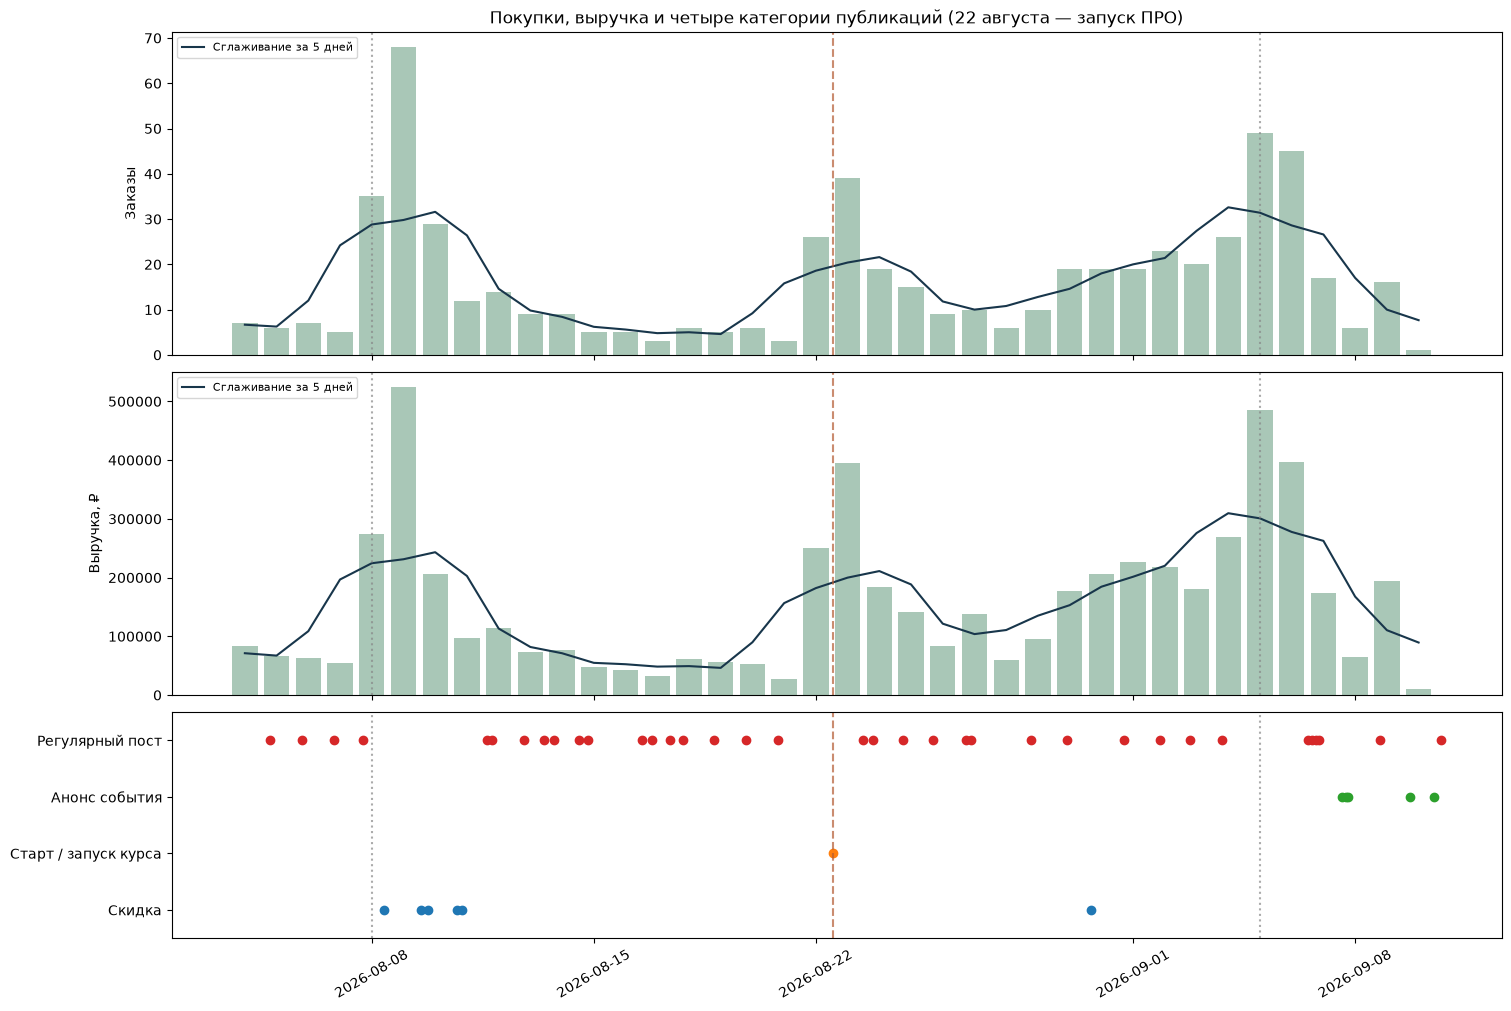

In [10]:
posts_daily = classified.groupby(["date", "post_type"]).size().unstack(fill_value=0).reset_index()
combined = daily.merge(posts_daily, on="date", how="left").fillna(0)
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True, constrained_layout=True, gridspec_kw={"height_ratios": [2, 2, 1.4]})
for ax, metric, label in zip(axes[:2], ["orders", "revenue"], ["Заказы", "Выручка, ₽"]):
    ax.bar(daily.date, daily[metric], color="#70a288", alpha=.6)
    ax.plot(daily.date, daily[metric].rolling(5, center=True, min_periods=1).mean(), color="#18364b", label="Сглаживание за 5 дней")
    ax.set_ylabel(label)
    ax.legend(loc="upper left", fontsize=8)
for i, (category, label) in enumerate(LABELS.items()):
    subset = classified[classified.post_type.eq(category)]
    axes[2].scatter(subset.event_timestamp, np.full(len(subset), i), s=36, label=label)
axes[2].set_yticks(range(len(LABELS)), list(LABELS.values()))
axes[2].set_ylim(-.5, len(LABELS)-.5)
for date, title in events_calendar.items():
    for ax in axes:
        ax.axvline(date, color="#888888", linestyle=":", alpha=.7)
for ax in axes:
    ax.axvline(pd.Timestamp("2026-08-22 13:19:48"), color="#b45c33", linestyle="--", alpha=.7)
axes[0].set_title("Покупки, выручка и четыре категории публикаций (22 августа — запуск ПРО)")
axes[2].tick_params(axis="x", rotation=30)
fig.savefig(CHART_DIR / "posts_sales.png", dpi=160, bbox_inches="tight")
plt.show()


Этот график — основная иллюстрация совместной динамики. Он позволяет увидеть, какие публикации выходили рядом со всплесками продаж, но не позволяет утверждать, что пост вызвал покупку: публикации частые, события перекрываются, а user-level source исторически отсутствует.

## 9. Event-study: продажи вокруг маркетинговых постов

Посты с полными окнами: 10 из 12


,revenue_24h_before,revenue_24h_after,revenue_24_48h_after
post_type,,,
course_launch,110550.0,249575.0,395468.0
discount,291795.0,231756.0,142052.0
event_announcement,270875.0,78700.0,139900.0


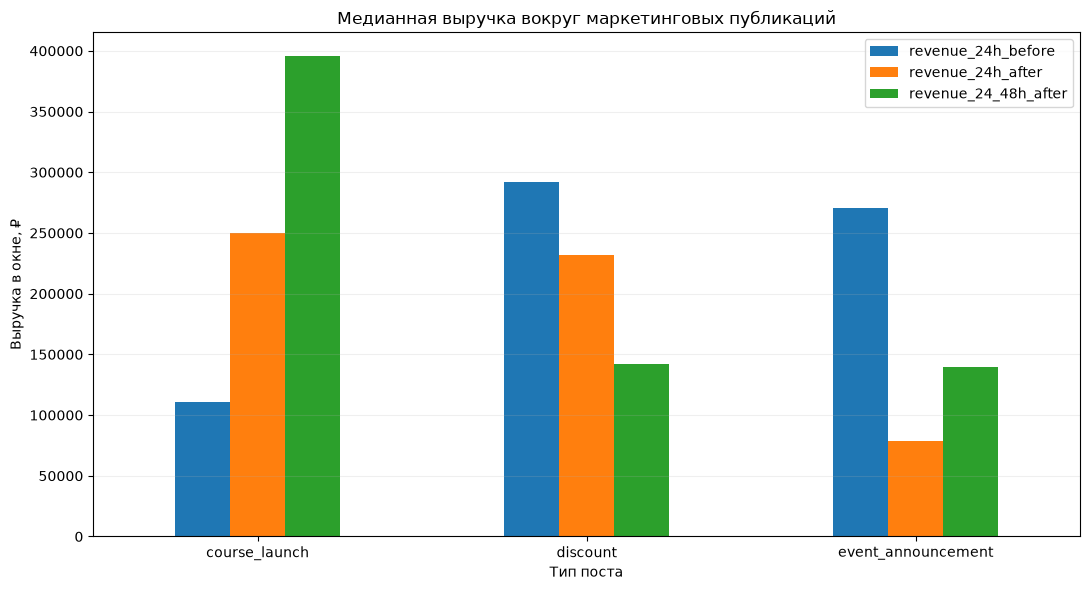

In [11]:
# Берём только типы, которые разумно рассматривать как маркетинговые события.
marketing_types = ["course_launch", "discount", "event_announcement"]
marketing_posts = classified[classified["post_type"].isin(marketing_types)].copy()

# Для каждого поста считаем revenue/orders в фиксированных окнах относительно точного времени публикации.
# Это описательная диагностика. Окна разных постов могут перекрываться.
def window_stats(post_ts):
    out = {}
    windows = {
        "24h_before": (post_ts - pd.Timedelta(hours=24), post_ts),
        "24h_after": (post_ts, post_ts + pd.Timedelta(hours=24)),
        "24_48h_after": (post_ts + pd.Timedelta(hours=24), post_ts + pd.Timedelta(hours=48)),
    }
    for name, (left, right) in windows.items():
        mask = (orders["Время"] >= left) & (orders["Время"] < right)
        out[f"revenue_{name}"] = orders.loc[mask, "order_amount"].sum()
        out[f"orders_{name}"] = int(mask.sum())
        out[f"complete_{name}"] = left >= sales["Время"].min() and right <= sales["Время"].max()
    return pd.Series(out)

if len(marketing_posts):
    event_study = marketing_posts.join(
        marketing_posts["event_timestamp"].apply(window_stats)
    )

    complete_columns = [c for c in event_study if c.startswith("complete_")]
    event_study_complete = event_study[event_study[complete_columns].all(axis=1)]
    print("Посты с полными окнами:", len(event_study_complete), "из", len(event_study))
    display(
        event_study_complete.groupby("post_type")[
            ["revenue_24h_before", "revenue_24h_after", "revenue_24_48h_after"]
        ].median().round(0)
    )

    event_plot = (
        event_study_complete.groupby("post_type")[
            ["revenue_24h_before", "revenue_24h_after", "revenue_24_48h_after"]
        ]
        .median()
    )

    ax = event_plot.plot(kind="bar", figsize=(11, 6))
    ax.set_title("Медианная выручка вокруг маркетинговых публикаций")
    ax.set_ylabel("Выручка в окне, ₽")
    ax.set_xlabel("Тип поста")
    ax.grid(axis="y", alpha=.2)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(CHART_DIR / "post_event_study.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Маркетинговые посты не найдены классификатором.")

### Ограничение event-study

Сравнение «24 часа до / после» полезно как sanity check, но **не является оценкой incremental lift**:
- посты могут выходить близко друг к другу;
- публикации могут планироваться именно на периоды ожидаемого спроса;
- на продажи влияют внешние события;
- неизвестно, видел ли конкретный покупатель конкретный пост.

Поэтому результат следует описывать как temporal association.

## 10. Дневная таблица: продажи + посты

In [12]:
daily_posts_total = (
    classified.groupby("date")
    .size()
    .rename("posts_total")
    .reset_index()
)

daily_marketing = (
    classified[classified["post_type"].isin(marketing_types)]
    .groupby("date")
    .size()
    .rename("marketing_posts")
    .reset_index()
)

daily_joined = (
    daily
    .merge(daily_posts_total, on="date", how="left")
    .merge(daily_marketing, on="date", how="left")
    .fillna({"posts_total": 0, "marketing_posts": 0})
)

daily_joined["posts_total"] = daily_joined["posts_total"].astype(int)
daily_joined["marketing_posts"] = daily_joined["marketing_posts"].astype(int)

display(daily_joined.head(15))

,date,revenue,orders,buyers,revenue_ma5,orders_ma5,posts_total,marketing_posts
0,2026-08-04,84130.00,7,6,71228.333333,6.666667,1,0
1,2026-08-05,67110.00,6,6,67170.000000,6.250000,1,0
2,2026-08-06,62445.00,7,7,108739.000000,12.000000,1,0
3,2026-08-07,54995.00,5,5,196731.334000,24.200000,1,0
4,2026-08-08,275015.00,35,35,224427.334000,28.800000,1,1
5,2026-08-09,524091.67,68,68,231204.334000,29.800000,2,2
6,2026-08-10,205590.00,29,29,243191.334000,31.600000,2,2
7,2026-08-11,96330.00,12,12,202750.334000,26.400000,2,0
8,2026-08-12,114930.00,14,14,113270.000000,14.600000,1,0
9,2026-08-13,72810.00,9,9,81821.000000,9.800000,2,0


### Почему не стоит считать простую корреляцию `posts_total` ↔ `revenue`

В периоде публикации выходят очень часто, а продажи имеют выраженную временную структуру. Обычная корреляция смешает:
- календарный спрос;
- число публикаций;
- тип публикации;
- внешние события.

Поэтому в EDA лучше оставить временной график и event-study как **описательную** диагностику, а causal effect измерять уже на новых данных через holdout / A/B / randomized promotion.

## 11. Что можно и нельзя заключить из исторических данных

In [13]:
summary = pd.DataFrame({
    "Можно измерить": [
        "Выручку и число заказов",
        "Продуктовый микс",
        "Bundle-заказы и реальные repeat orders",
        "Динамику спроса внутри периода",
        "Даты и типы публикаций собственного Telegram-канала",
        "Временную ассоциацию продаж и публикаций",
    ],
    "Нельзя восстановить надежно": [
        "Какой конкретно пост увидел покупатель",
        "Paid external placement для каждой покупки",
        "Истинный incremental lift поста",
        "Исторический ROMI внешней рекламы",
        "Полную годовую сезонность по 38 дням",
        "Причинность из совпадения поста и всплеска продаж",
    ]
})
display(summary)

,Можно измерить,Нельзя восстановить надежно
0,Выручку и число заказов,Какой конкретно пост увидел покупатель
1,Продуктовый микс,Paid external placement для каждой покупки
2,Bundle-заказы и реальные repeat orders,Истинный incremental lift поста
3,Динамику спроса внутри периода,Исторический ROMI внешней рекламы
4,Даты и типы публикаций собственного Telegram-канала,Полную годовую сезонность по 38 дням
5,Временную ассоциацию продаж и публикаций,Причинность из совпадения поста и всплеска продаж


## Итог

Историческая база хорошо описывает **что купили, когда и на какую сумму**, а Telegram export — **что и когда публиковалось**. После перехода на уровень заказа bundle-строки больше не искажают repeat purchase.

Совмещение по timestamp позволяет визуально и через event-study исследовать временную связь публикаций и продаж. Но исторически отсутствует ключевая связь `placement → user → touch → lead → order`, поэтому attribution ROMI и incremental effect из этого EDA не выводятся.

Именно этот пробел закрывает measurement-flow Telegram-бота: новые кампании должны собирать source/placement и user-level касания с момента запуска.

## 12. Проверка пика 22 августа

22 августа в 13:19:48 опубликован пост №1859 о запуске линейки ПРО. Это проверенный анонс запуска, скидка в этом тексте не заявлена. Сравниваем покупки до публикации и после неё; рост до публикации не может быть её следствием. Данные описывают временную связь, но не позволяют приписать посту все последующие продажи. Важны другие коммуникации, время суток и календарный спрос.


,post_id,event_timestamp,post_type,classification_reason,post_text
20,1855,2026-08-18 19:05:48,regular,Автоматическая разметка; требует просмотра текста,"Наш студент прошёл больше шести этапов собеседований, получил два оффера - и остался ни с чем. Почему? Поучительная история в новом роли..."
21,1856,2026-08-19 18:58:14,regular,Автоматическая разметка; требует просмотра текста,"Полный цикл отбора в Fast Forward на кванта (HFT) \n\nЛучший хфт фонд в России с офисом, что для хфт особенно важно. Весь нетворкинг про..."
22,1857,2026-08-20 19:11:50,regular,Автоматическая разметка; требует просмотра текста,"Собрали 9 не самых очевидных стажировок в IT, которые стоит держать на радаре\n\nНе ограничились ссылками на карьерные сайты: по каждой ..."
23,1859,2026-08-22 13:19:48,course_launch,Мы запускаем ПРО; открываем пять направлений; дата старта занятий не указана,"Выходим на новый уровень с линейкой 1️⃣1️⃣1️⃣\n\nТоварищи, если база уже есть, то следующий шаг — углубиться в специализацию, закрыть пр..."
24,1860,2026-08-23 11:51:41,regular,Автоматическая разметка; требует просмотра текста,"Анализ айти рынка \n\nВ чате очень часто просят поделиться экспертизой по стоянию айти рынка на сегодняшнее время. Грубо говоря, к чему ..."
25,1863,2026-08-23 19:20:03,regular,Автоматическая разметка; требует просмотра текста,"Полный цикл собесов на Go-разработчика в Авито\n\nВ посте разберемся, как на самом деле устроен наём в Авито. Свёл официальный плейбук к..."
26,1865,2026-08-24 18:10:23,regular,Автоматическая разметка; требует просмотра текста,Какие пет проекты гарантирует тебе оффер на аналитика? Обсудим в новом ролике. Смотрим! Смотрим!\n\nhttps://www.youtube.com/watch?v=6dk8...
27,1866,2026-08-25 16:51:47,regular,Автоматическая разметка; требует просмотра текста,"Продолжаем знакомиться с талантливыми учениками ""Поступашек"". Сегодня в гостях - Никита, наш ученик, который поступил в ШАД. Несмотря на..."


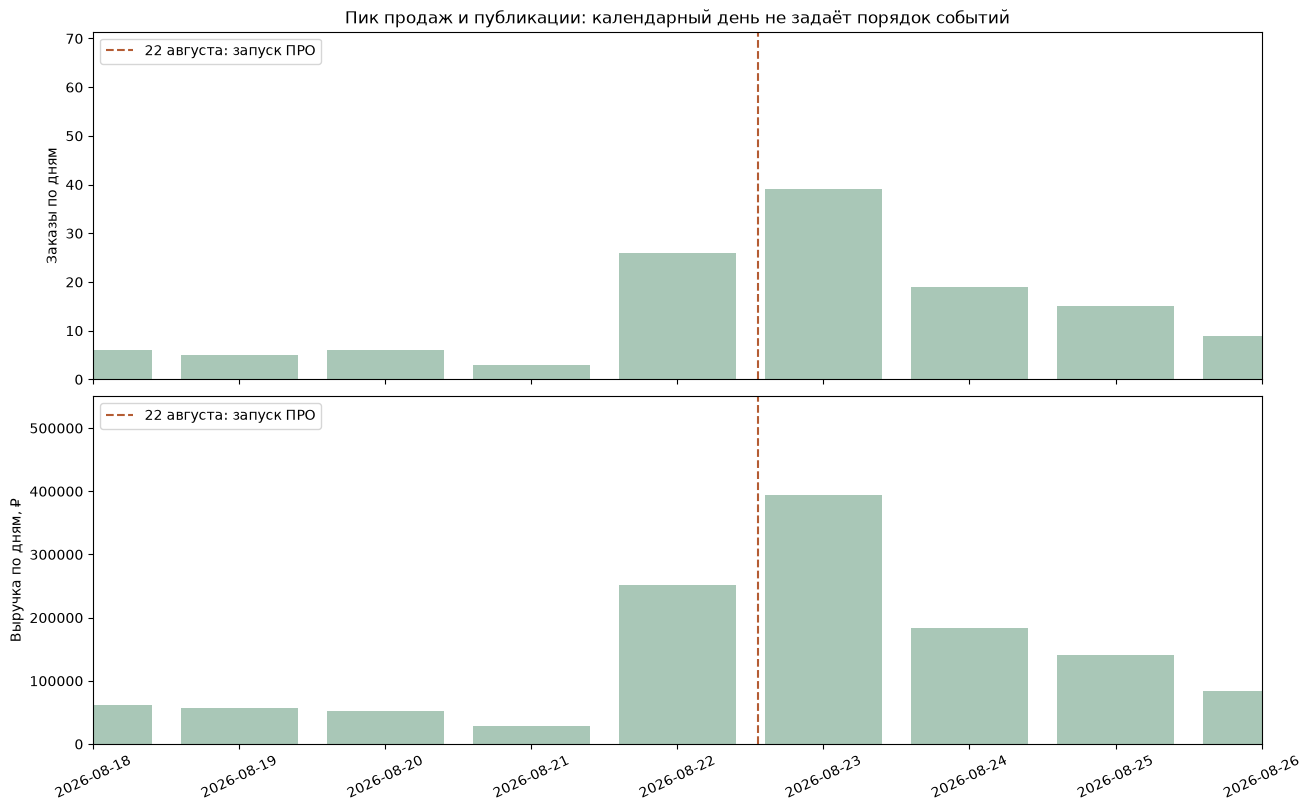

,window,start,end,orders,revenue,complete
0,22 августа до поста,2026-08-22 00:00:00,2026-08-22 13:19:48,10,100600.0,True
1,22 августа после поста,2026-08-22 13:19:48,2026-08-23 00:00:00,16,150550.0,True
2,24 часа до,2026-08-21 13:19:48,2026-08-22 13:19:48,11,110550.0,True
3,24 часа после,2026-08-22 13:19:48,2026-08-23 13:19:48,26,249575.0,True


courses
ML про              7
Аналитика про       5
Аналитика старт     4
Алгоритмы           3
Алгоритмы про       3
AI агенты           3
Backend про         2
ML старт            2
Линейная алгебра    1
Алгоритмы старт     1
Name: count, dtype: int64

In [14]:
focus_start, focus_end = pd.Timestamp("2026-08-18"), pd.Timestamp("2026-08-26")
focus_posts = classified[classified.event_timestamp.between(focus_start, focus_end, inclusive="left")]
display(focus_posts[["post_id", "event_timestamp", "post_type", "classification_reason", "post_text"]])
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True, constrained_layout=True)
for ax, metric, title in zip(axes, ["orders", "revenue"], ["Заказы по дням", "Выручка по дням, ₽"]):
    ax.bar(daily.date, daily[metric], color="#70a288", alpha=.6)
    ax.set_ylabel(title)
    for pid, color, label in [(1859, "#b45c33", "22 августа: запуск ПРО")]:
        timestamp = classified.loc[classified.post_id.eq(pid), "event_timestamp"].iloc[0]
        ax.axvline(timestamp, color=color, linestyle="--", label=label)
    ax.legend(loc="upper left")
axes[0].set_title("Пик продаж и публикации: календарный день не задаёт порядок событий")
axes[1].set_xlim(focus_start, focus_end)
axes[1].tick_params(axis="x", rotation=25)
plt.show()
fig.savefig(CHART_DIR / "aug22_launch_sales.png", dpi=160, bbox_inches="tight")
published = classified.loc[classified.post_id.eq(1859), "event_timestamp"].iloc[0]
rows = []
for name, left, right in [("22 августа до поста", published.normalize(), published),
                          ("22 августа после поста", published, published.normalize()+pd.Timedelta(days=1)),
                          ("24 часа до", published-pd.Timedelta(hours=24), published),
                          ("24 часа после", published, published+pd.Timedelta(hours=24))]:
    selected = orders[orders["Время"].ge(left) & orders["Время"].lt(right)]
    rows.append(dict(window=name, start=left, end=right, orders=len(selected), revenue=selected.order_amount.sum(),
                     complete=left>=sales["Время"].min() and right<=sales["Время"].max()))
launch_windows = pd.DataFrame(rows)
display(launch_windows)
display(orders[orders["Время"].ge(published) & orders["Время"].lt(published+pd.Timedelta(hours=24))].explode("courses").courses.value_counts())
